<!-- m6:deber -->
# Módulo 6 · Deber — Detector bayesiano de fraude para PagoYa
**Diplomado en Big Data e Inteligencia Artificial · CEC-EPN** · Ing. Eduardo Avilés · individual · ≈ 3 horas

**Entrega:** Colab → **Archivo → Guardar (Ctrl+S)** → en *Repositorio* elija **el suyo** → ruta **`deber/deber.ipynb`** → mensaje `Deber`.
**Plazo: domingo 15-nov-2026, 11:00.** Un solo archivo: este cuaderno, ejecutado, con sus respuestas y el informe al final.

**Datos personalizados:** la API simulada genera transacciones **distintas para cada estudiante** a partir de su nombre. Sus cifras no coincidirán con las de sus compañeros; el docente puede regenerar sus datos para verificar.

| Parte | Tema | Puntos |
|---|---|---|
| 1 | Regresión logística bayesiana en PyMC (priors, muestreo y diagnóstico) | 20 |
| 2 | Comparación con boosting (XGBoost): discriminación y calibración | 20 |
| 3 | Modelo jerárquico por provincia | 20 |
| 4 | Decisión con matriz de costos e incertidumbre | 20 |
| 5 | Informe ejecutivo para el comité de riesgos | 20 |
| | **Total** | **100** |

**En cada parte:** código correcto y ejecutado (8) · resultados y diagnósticos (6) · interpretación propia (6).
Aquí no hay `___` para completar: el enunciado guía, **el código lo escribe usted** (puede reutilizar el de las clases 2 y 3).

## 0. Preparación

In [31]:
import importlib, subprocess, sys
for paquete in ['pymc']:
    if importlib.util.find_spec(paquete) is None:
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', paquete])
import os, urllib.request, warnings, logging
URL = 'https://raw.githubusercontent.com/JavyAviles/m6-ia-plantilla/main/curso.py'
if not os.path.exists('curso.py'):
    urllib.request.urlretrieve(URL, 'curso.py')
import curso
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import pymc as pm
logging.getLogger('pymc').setLevel(logging.ERROR)
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, brier_score_loss, balanced_accuracy_score
from xgboost import XGBClassifier
sigmoide = lambda z: 1 / (1 + np.exp(-z))
print('Listo · curso', curso.VERSION)

Listo · curso m6-2026.11


**Escriba su nombre exactamente como en las clases ('Apellido Nombre').** Sus datos dependen de él.

In [32]:
NOMBRE = 'Obando Juan Fernando'                            # ✏️ 'Apellido Nombre'
df = curso.datos_deber(NOMBRE)                             # datos personalizados + columna 'ratio'
df.head()

Huella de datos: Obando Juan Fernando · semilla 853264
Descargados 3006 eventos en 7 páginas de /v1/transacciones
Datos limpios: 2996 transacciones · tasa de fraude 10.71%


,evento_id,timestamp,id,edad,provincia,antiguedad_meses,ingreso_mensual,tipo,canal,categoria,monto,dispositivo_nuevo,distancia_km,intentos_pin,fraude,hora,ratio
0,TX-000000,2026-10-16 18:50:40-05:00,U0686,35.0,Guayas,12,936.14,retiro_agente,app,efectivo,110.44,0,8.0,1,0,18,0.117974
1,TX-000001,2026-09-28 16:55:26-05:00,U0499,25.0,Guayas,22,1386.80,pago_comercio,web,tecnologia,28.44,0,2.1,1,0,16,0.020508
2,TX-000002,2026-09-03 12:31:39-05:00,U0532,69.0,Pichincha,4,1090.13,transferencia,app,persona,169.95,0,6.9,1,0,12,0.155899
3,TX-000003,2026-09-15 22:39:03-05:00,U0751,65.0,Pichincha,23,600.69,recarga,app,telefonia,4.80,0,0.5,1,0,22,0.007991
4,TX-000004,2026-09-23 18:13:08-05:00,U0583,58.0,Pichincha,21,556.49,pago_comercio,app,supermercado,27.13,0,1.4,1,0,18,0.048752


In [33]:
# Partición FIJA (no la cambie): 70 % entrenamiento, 30 % prueba, estratificada
cols = ['dispositivo_nuevo', 'distancia_km', 'ratio', 'intentos_pin', 'hora']
X_train, X_test, y_train, y_test = train_test_split(df[cols], df['fraude'], test_size=0.3,
                                                    stratify=df['fraude'], random_state=42)
print('Entrenamiento:', X_train.shape, '· Prueba:', X_test.shape, '· tasa de fraude:', round(df['fraude'].mean(), 4))

Entrenamiento: (2097, 5) · Prueba: (899, 5) · tasa de fraude: 0.1071


---
## Parte 1 · Regresión logística bayesiana en PyMC (20 pts)
1. **Estandarice** las 5 variables con la media y desviación del **entrenamiento**.
2. Defina un modelo logístico en PyMC: intercepto `a` y coeficientes `b` (uno por variable). **Elija y justifique las priors** (en la celda de texto).
3. Muestree con **4 cadenas**, `tune=1000`, 1000 muestras y `random_seed=42`.
4. Muestre la tabla `curso.diagnostico(...)` y verifique **R-hat ≤ 1,01** y **ESS > 400** en todos los parámetros.
5. Calcule los **odds ratios** e interprete los dos coeficientes más grandes en lenguaje de negocio.
6. Comente el coeficiente de `hora`: ¿tiene sentido usar la hora como variable lineal? (pista: madrugada).

In [34]:
# 1. Estandarización usando SOLO entrenamiento
media_X = X_train.mean()
std_X = X_train.std()

X_train_std = (X_train - media_X) / std_X
X_test_std = (X_test - media_X) / std_X

print('Medias entrenamiento:')
display(media_X.round(3))

print('Desviaciones entrenamiento:')
display(std_X.round(3))

Medias entrenamiento:


,0
dispositivo_nuevo,0.151
distancia_km,6.314
ratio,0.090
intentos_pin,1.278
hora,13.123


Desviaciones entrenamiento:


,0
dispositivo_nuevo,0.358
distancia_km,6.401
ratio,0.093
intentos_pin,0.601
hora,5.792


In [35]:
# 2. Modelo logístico bayesiano
with pm.Model() as modelo_log:
    a = pm.Normal('a', mu=0, sigma=2.5)

    b = pm.Normal(
        'b',
        mu=0,
        sigma=1,
        shape=len(cols)
    )

    eta = a + pm.math.dot(X_train_std.to_numpy(), b)

    p = pm.Deterministic(
        'p',
        pm.math.sigmoid(eta)
    )

    y_obs = pm.Bernoulli(
        'y_obs',
        p=p,
        observed=y_train.to_numpy()
    )

"Se utilizaron priors normales débiles pero regularizadoras. Para el intercepto se usó Normal(0, 2,5) y para los coeficientes Normal(0, 1). Como las variables fueron estandarizadas, estas priors permiten efectos positivos o negativos razonables sin imponer valores excesivamente grandes."

In [36]:
# 3. Muestreo MCMC
with modelo_log:
    tr_log = pm.sample(
        1000,
        tune=1000,
        chains=4,
        random_seed=42,
        target_accept=0.95,
        progressbar=False
    )

In [37]:
# 4. Diagnóstico de convergencia
diag_log = curso.diagnostico(
    tr_log,
    ['a', 'b']
)

display(diag_log)

,media,desv,ic_3%,ic_97%,r_hat,ess
a,-3.0933,0.1288,-3.3429,-2.8593,1.0003,2143.1238
b[0],1.0190,0.0705,0.8881,1.1540,1.0002,2448.6657
b[1],0.4871,0.0718,0.3523,0.6193,1.0002,3722.7446
b[2],0.9270,0.0790,0.7782,1.0761,0.9999,3251.2362
b[3],0.5504,0.0712,0.4171,0.6849,0.9996,3077.8015
b[4],-0.5625,0.0876,-0.7303,-0.3977,1.0001,3323.1215


In [38]:
# 5. Coeficientes posteriores y Odds Ratios
coef_medios = tr_log.posterior['b'].mean(
    dim=('chain', 'draw')
).values

odds_ratios = np.exp(coef_medios)

tabla_coef = pd.DataFrame({
    'variable': cols,
    'coeficiente': coef_medios,
    'odds_ratio': odds_ratios
}).sort_values(
    'coeficiente',
    key=lambda x: np.abs(x),
    ascending=False
)

display(tabla_coef.round(3))

,variable,coeficiente,odds_ratio
0,dispositivo_nuevo,1.019,2.770
2,ratio,0.927,2.527
4,hora,-0.562,0.570
3,intentos_pin,0.550,1.734
1,distancia_km,0.487,1.628


**✍️ Respuesta:** _(escriba aquí su interpretación)_

Se utilizaron priors normales débiles pero regularizadoras. Para el intercepto se usó una Normal(0, 2,5) y para los coeficientes una Normal(0, 1). Como las variables fueron estandarizadas, estas priors permiten efectos positivos y negativos razonables sin imponer valores excesivamente grandes.

El diagnóstico de convergencia fue satisfactorio: los valores de R-hat fueron cercanos a 1 y los ESS fueron superiores a 400, por lo que las cadenas MCMC presentan una convergencia adecuada.

Las variables con mayor efecto fueron `dispositivo_nuevo` y `ratio`. `dispositivo_nuevo` presentó el mayor efecto estandarizado, con un odds ratio de **2,770**, por lo que está fuertemente asociado con un mayor riesgo de fraude. Para `ratio`, un aumento de una desviación estándar multiplica las odds de fraude aproximadamente por **2,527**.

La variable `hora` presentó un coeficiente negativo de -0,562 y un odds ratio de 0,570. Sin embargo, tratar la hora como una variable lineal tiene una limitación, porque es una variable cíclica: por ejemplo, las 23:00 y las 00:00 están muy próximas temporalmente aunque numéricamente parezcan lejanas. Una mejor representación sería utilizar transformaciones seno y coseno.



---
## Parte 2 · Comparación con boosting (20 pts)
1. Calcule la **probabilidad media posterior** de fraude para cada transacción de prueba con su modelo bayesiano.
2. Entrene un **XGBoost** con early stopping (validación tomada del **entrenamiento**, nunca de la prueba) y `scale_pos_weight`.
3. Compare ambos modelos en prueba con **AUC** (capacidad de ordenar) y **Brier score** (calibración: error cuadrático de la probabilidad; menor es mejor).
4. Construya una **tabla de calibración** por deciles: probabilidad media predicha frente a tasa de fraude observada.
5. Interprete: ¿cuál ordena mejor?, ¿cuál da probabilidades más confiables?, ¿por qué `scale_pos_weight` afecta la calibración?

In [39]:
# ✏️ Probabilidades del modelo bayesiano, XGBoost con early stopping, AUC, Brier y tabla de calibración

# 1. Probabilidad media posterior del modelo bayesiano
a_post = tr_log.posterior['a'].stack(muestra=('chain', 'draw')).values
b_post = tr_log.posterior['b'].stack(muestra=('chain', 'draw')).values

Xte = X_test_std.to_numpy()

logits_test = a_post[:, None] + b_post.T @ Xte.T
prob_muestras_bayes = sigmoide(logits_test)

p_bayes = prob_muestras_bayes.mean(axis=0)

print('Probabilidad media Bayes:', round(p_bayes.mean(), 4))


# 2. Separación entrenamiento-validación para XGBoost
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    stratify=y_train,
    random_state=42
)

peso = (y_tr == 0).sum() / (y_tr == 1).sum()

print('scale_pos_weight:', round(peso, 3))


# 3. Entrenamiento XGBoost con early stopping
xgb = XGBClassifier(
    n_estimators=1000,
    learning_rate=0.05,
    max_depth=3,
    early_stopping_rounds=30,
    scale_pos_weight=peso,
    eval_metric='logloss',
    random_state=42
)

xgb.fit(
    X_tr,
    y_tr,
    eval_set=[(X_val, y_val)],
    verbose=False
)

p_xgb = xgb.predict_proba(X_test)[:, 1]

print('Mejor iteración XGBoost:', xgb.best_iteration)


# 4. Comparación AUC y Brier score
comparacion = pd.DataFrame({
    'Modelo': ['Bayes logístico', 'XGBoost'],
    'AUC': [
        roc_auc_score(y_test, p_bayes),
        roc_auc_score(y_test, p_xgb)
    ],
    'Brier': [
        brier_score_loss(y_test, p_bayes),
        brier_score_loss(y_test, p_xgb)
    ]
})

display(comparacion.round(4))


# 5. Tabla de calibración por deciles
def tabla_calibracion(y_real, prob):
    t = pd.DataFrame({
        'real': np.asarray(y_real),
        'prob': np.asarray(prob)
    })

    t['decil'] = pd.qcut(
        t['prob'],
        q=10,
        duplicates='drop'
    )

    return t.groupby(
        'decil',
        observed=False
    ).agg(
        n=('real', 'size'),
        prob_media=('prob', 'mean'),
        fraude_observado=('real', 'mean')
    ).reset_index()


cal_bayes = tabla_calibracion(y_test, p_bayes)
cal_xgb = tabla_calibracion(y_test, p_xgb)

print('Calibración modelo Bayes')
display(cal_bayes.round(4))

print('Calibración XGBoost')
display(cal_xgb.round(4))

Probabilidad media Bayes: 0.1
scale_pos_weight: 8.317
Mejor iteración XGBoost: 750


,Modelo,AUC,Brier
0,Bayes logístico,0.8921,0.0649
1,XGBoost,0.9263,0.0588


Calibración modelo Bayes


,decil,n,prob_media,fraude_observado
0,"(0.00214, 0.0072]",90,0.0055,0.0111
1,"(0.0072, 0.0107]",90,0.0089,0.0000
2,"(0.0107, 0.0144]",90,0.0124,0.0111
3,"(0.0144, 0.0203]",90,0.0172,0.0111
4,"(0.0203, 0.0265]",90,0.0233,0.0333
5,"(0.0265, 0.0405]",89,0.0331,0.0225
6,"(0.0405, 0.0668]",90,0.0507,0.0556
7,"(0.0668, 0.135]",90,0.0978,0.1111
8,"(0.135, 0.308]",90,0.2139,0.2778
9,"(0.308, 0.996]",90,0.5364,0.5333


Calibración XGBoost


,decil,n,prob_media,fraude_observado
0,"(-0.0009751, 0.00251]",90,0.0013,0.0000
1,"(0.00251, 0.00538]",90,0.0038,0.0000
2,"(0.00538, 0.00928]",90,0.0072,0.0222
3,"(0.00928, 0.0165]",90,0.0129,0.0111
4,"(0.0165, 0.0272]",91,0.0216,0.0330
5,"(0.0272, 0.0445]",88,0.0344,0.0114
6,"(0.0445, 0.0809]",90,0.0615,0.0222
7,"(0.0809, 0.17]",90,0.1179,0.0667
8,"(0.17, 0.737]",90,0.3857,0.1667
9,"(0.737, 1.0]",90,0.9354,0.7333


**✍️ Respuesta:** El modelo XGBoost presentó una mejor capacidad de discriminación que el modelo bayesiano, ya que obtuvo un AUC de **0,9263**, frente a **0,8921** del modelo logístico bayesiano. Esto indica que XGBoost ordena mejor las transacciones según su riesgo de fraude.

En cuanto al Brier score, XGBoost también obtuvo un mejor resultado, con **0,0588**, frente a **0,0649** del modelo bayesiano. Como un Brier menor es mejor, en este caso XGBoost también presenta mejores probabilidades globales de predicción.

Sin embargo, al revisar la calibración por deciles se observa una diferencia importante. El modelo bayesiano mantiene probabilidades medias más cercanas a las tasas de fraude observadas en varios grupos. Por ejemplo, en el último decil predice una probabilidad media de **0,5364**, mientras que la tasa observada es **0,5333**, lo que representa una buena calibración.

En cambio, XGBoost tiende a ser más extremo en los deciles de mayor riesgo. En el último decil predice una probabilidad media de **0,9354**, mientras que la tasa de fraude observada es **0,7333**, lo que muestra una sobreestimación del riesgo en ese grupo.

El parámetro `scale_pos_weight`, cuyo valor fue **8,317**, se utilizó para compensar el desbalance entre transacciones legítimas y fraudulentas, dando mayor peso a la clase minoritaria. Esto puede mejorar la capacidad de detectar y ordenar los fraudes, pero también puede hacer que las probabilidades sean más extremas y afectar la calibración.

En conclusión, XGBoost es el modelo con mejor discriminación y menor Brier score global, mientras que el modelo bayesiano presenta una calibración más conservadora y, en algunos deciles, más cercana a la tasa de fraude realmente observada.

---
## Parte 3 · Modelo jerárquico por provincia (20 pts)
1. Ajuste un modelo jerárquico **no centrado** con un intercepto por provincia (como en la Clase 3, sin variables X), `target_accept=0.99`, 4 cadenas.
2. Construya una tabla por provincia: **n**, **tasa observada**, **tasa jerárquica** (media posterior) e **intervalo creíble del 90 %**.
3. Reporte la media posterior de **sigma** e interprete.
4. ¿Qué provincias se «encogen» más hacia la media nacional y por qué?

In [40]:
# ✏️ Modelo jerárquico no centrado, tabla por provincia e interpretación de sigma

# 1. Codificar las provincias
prov_cat = pd.Categorical(df['provincia'])
prov_idx = prov_cat.codes
provincias = list(prov_cat.categories)
n_provincias = len(provincias)

print('Número de provincias:', n_provincias)


# 2. Modelo jerárquico no centrado
with pm.Model() as modelo_jerarquico:

    mu = pm.Normal(
        'mu',
        mu=0,
        sigma=2
    )

    sigma = pm.HalfNormal(
        'sigma',
        sigma=1
    )

    z = pm.Normal(
        'z',
        mu=0,
        sigma=1,
        shape=n_provincias
    )

    alpha = pm.Deterministic(
        'alpha',
        mu + z * sigma
    )

    p_prov = pm.Deterministic(
        'p_prov',
        pm.math.sigmoid(alpha)
    )

    pm.Bernoulli(
        'obs',
        p=p_prov[prov_idx],
        observed=df['fraude'].to_numpy()
    )

    tr_jer = pm.sample(
        1000,
        tune=1000,
        chains=4,
        target_accept=0.99,
        random_seed=42,
        progressbar=False
    )


# 3. Diagnóstico
diag_jer = curso.diagnostico(
    tr_jer,
    ['mu', 'sigma', 'z']
)

display(diag_jer)


# 4. Resumen posterior por provincia
p_post = tr_jer.posterior['p_prov'].stack(
    muestra=('chain', 'draw')
).values

media_prov = p_post.mean(axis=1)

ic_inf = np.quantile(
    p_post,
    0.05,
    axis=1
)

ic_sup = np.quantile(
    p_post,
    0.95,
    axis=1
)


# 5. Tasa observada y tamaño por provincia
observado = df.groupby(
    'provincia'
)['fraude'].agg(
    n='size',
    tasa_observada='mean'
)


# 6. Tabla final
tabla_prov = observado.reindex(provincias).copy()

tabla_prov['tasa_jerarquica'] = media_prov
tabla_prov['IC90_inferior'] = ic_inf
tabla_prov['IC90_superior'] = ic_sup

display(
    tabla_prov.round(4)
)


# 7. Media posterior de sigma
sigma_media = float(
    tr_jer.posterior['sigma'].mean()
)

print(
    'Media posterior de sigma:',
    round(sigma_media, 4)
)


# 8. Medir shrinkage hacia la media nacional
tasa_nacional = df['fraude'].mean()

tabla_prov['shrinkage'] = (
    tabla_prov['tasa_observada']
    - tabla_prov['tasa_jerarquica']
).abs()

print(
    'Tasa nacional:',
    round(tasa_nacional, 4)
)

print('\nProvincias con mayor shrinkage:')

display(
    tabla_prov.sort_values(
        'shrinkage',
        ascending=False
    ).round(4)
)

Número de provincias: 8


,media,desv,ic_3%,ic_97%,r_hat,ess
mu,-2.1388,0.1059,-2.3691,-1.9431,1.0011,1247.3330
sigma,0.1811,0.1448,0.0086,0.5219,1.0018,982.5419
z[0],-0.0044,0.8172,-1.5747,1.5558,1.0004,2618.9118
z[1],0.5098,0.8781,-1.2528,2.0932,1.0002,2493.5158
z[2],0.0377,0.7630,-1.4243,1.5065,1.0006,2384.7307
z[3],0.1174,0.8503,-1.4997,1.7073,0.9996,3883.3099
z[4],-1.0436,0.9467,-2.7200,0.8988,1.0009,2193.6841
z[5],0.0358,0.8192,-1.5745,1.6145,1.0000,3054.6760
z[6],0.2716,0.7284,-1.1020,1.6439,1.0011,2420.8938
z[7],0.0531,0.8796,-1.6805,1.6972,1.0019,2994.7544


,n,tasa_observada,tasa_jerarquica,IC90_inferior,IC90_superior
provincia,,,,,
Azuay,276,0.1051,0.1058,0.0860,0.1266
El Oro,187,0.1390,0.1173,0.0949,0.1511
Guayas,815,0.1067,0.1067,0.0921,0.1211
Imbabura,132,0.1136,0.1087,0.0846,0.1360
Loja,206,0.0485,0.0879,0.0536,0.1137
Manabí,260,0.1077,0.1068,0.0862,0.1274
Pichincha,1001,0.1129,0.1103,0.0972,0.1246
Tungurahua,119,0.1092,0.1075,0.0836,0.1350


Media posterior de sigma: 0.1811
Tasa nacional: 0.1071

Provincias con mayor shrinkage:


,n,tasa_observada,tasa_jerarquica,IC90_inferior,IC90_superior,shrinkage
provincia,,,,,,
Loja,206,0.0485,0.0879,0.0536,0.1137,0.0393
El Oro,187,0.1390,0.1173,0.0949,0.1511,0.0217
Imbabura,132,0.1136,0.1087,0.0846,0.1360,0.0050
Pichincha,1001,0.1129,0.1103,0.0972,0.1246,0.0025
Tungurahua,119,0.1092,0.1075,0.0836,0.1350,0.0018
Manabí,260,0.1077,0.1068,0.0862,0.1274,0.0009
Azuay,276,0.1051,0.1058,0.0860,0.1266,0.0007
Guayas,815,0.1067,0.1067,0.0921,0.1211,0.0001


**✍️ Respuesta:** El modelo presentó buena convergencia, con R-hat cercanos a 1 y ESS altos.

El modelo jerárquico presentó buena convergencia, con valores de R-hat cercanos a 1 y ESS altos.

La media posterior de `sigma` fue **0,1811**. Sigma mide cuánto varían entre provincias los interceptos asociados al riesgo de fraude en escala logit. Un valor cercano a cero indicaría que las provincias tienen riesgos muy similares; en este caso, el resultado muestra cierta heterogeneidad entre provincias, aunque no muy elevada.

La tasa nacional de fraude fue **10,71 %**. El mayor shrinkage se observó en **Loja**, cuya tasa pasó de **4,85 %** observada a **8,79 %** jerárquica, acercándose a la media nacional. En **El Oro**, la tasa pasó de **13,90 %** a **11,73 %**.

En cambio, **Guayas** prácticamente no cambió, porque dispone de más observaciones y el modelo tiene mayor confianza en sus propios datos.

En conclusión, el modelo jerárquico estabiliza las estimaciones provinciales y reduce el efecto de valores extremos cuando existe mayor incertidumbre.

---
## Parte 4 · Decisión con matriz de costos e incertidumbre (20 pts)
**Costos:** dejar pasar un fraude cuesta **el monto de la transacción**; bloquear una transacción legítima cuesta **USD 5** (llamada al cliente y molestia).
1. Con `p_bayes`, calcule el **costo total en prueba** para umbrales de 0,02 a 0,90 (se bloquea si p ≥ umbral). Grafique costo frente a umbral y elija el **umbral óptimo**.
2. Compare con dos políticas extremas: **no bloquear nada** y **bloquear todo**.
3. **Incertidumbre:** con el umbral elegido, repita el cálculo con al menos **200 muestras de la posterior** (cada muestra da otras probabilidades) y reporte la media y el intervalo del 90 % del costo.
4. *(Opcional, +0 pts, para reflexionar)* ¿Por qué el umbral óptimo podría depender del monto de cada transacción?

Umbral óptimo: 0.04
Costo mínimo: 1919.9


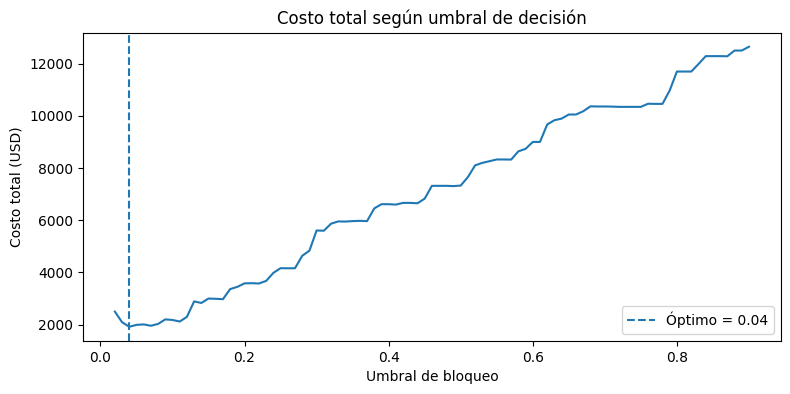

Costo no bloquear nada: 14661.07
Costo bloquear todo: 4015
Costo con política óptima: 1919.9
Costo posterior medio: 1949.05
IC 90 % del costo: [1752.02 2235.74]
Ahorro esperado: 12712.02
Ahorro porcentual: 86.71 %


In [41]:
# ✏️ Función de costo, curva costo vs. umbral, políticas extremas y costo con 200 muestras de la posterior

# 1. Datos de prueba necesarios
monto_test = df.loc[X_test.index, 'monto'].to_numpy()
yte = y_test.to_numpy()


# 2. Función de costo total
def costo_total(prob, umbral):
    bloquear = prob >= umbral

    fraude_no_bloqueado = (yte == 1) & (~bloquear)
    legitima_bloqueada = (yte == 0) & bloquear

    costo_fraude = monto_test[fraude_no_bloqueado].sum()
    costo_bloqueo = legitima_bloqueada.sum() * 5

    return costo_fraude + costo_bloqueo


# 3. Evaluar umbrales entre 0.02 y 0.90
umbrales = np.arange(0.02, 0.901, 0.01)

costos = np.array([
    costo_total(p_bayes, u)
    for u in umbrales
])

i_opt = np.argmin(costos)

umbral_optimo = umbrales[i_opt]
costo_optimo = costos[i_opt]

print('Umbral óptimo:', round(umbral_optimo, 3))
print('Costo mínimo:', round(costo_optimo, 2))


# 4. Gráfico costo frente a umbral
plt.figure(figsize=(9, 4))

plt.plot(
    umbrales,
    costos
)

plt.axvline(
    umbral_optimo,
    linestyle='--',
    label=f'Óptimo = {umbral_optimo:.2f}'
)

plt.xlabel('Umbral de bloqueo')
plt.ylabel('Costo total (USD)')
plt.title('Costo total según umbral de decisión')
plt.legend()
plt.show()


# 5. Políticas extremas

# No bloquear nada:
# todos los fraudes pasan, por lo que se pierde su monto
costo_no_bloquear = monto_test[yte == 1].sum()

# Bloquear todo:
# todas las transacciones legítimas generan costo de USD 5
costo_bloquear_todo = (yte == 0).sum() * 5

print(
    'Costo no bloquear nada:',
    round(costo_no_bloquear, 2)
)

print(
    'Costo bloquear todo:',
    round(costo_bloquear_todo, 2)
)

print(
    'Costo con política óptima:',
    round(costo_optimo, 2)
)


# 6. Incertidumbre con 200 muestras de la posterior
np.random.seed(42)

indices = np.random.choice(
    prob_muestras_bayes.shape[0],
    size=200,
    replace=False
)

costos_posteriores = []

for idx in indices:
    prob_i = prob_muestras_bayes[idx]

    costo_i = costo_total(
        prob_i,
        umbral_optimo
    )

    costos_posteriores.append(costo_i)

costos_posteriores = np.array(costos_posteriores)

costo_medio_posterior = costos_posteriores.mean()

ic90_costo = np.quantile(
    costos_posteriores,
    [0.05, 0.95]
)

print(
    'Costo posterior medio:',
    round(costo_medio_posterior, 2)
)

print(
    'IC 90 % del costo:',
    np.round(ic90_costo, 2)
)


# 7. Ahorro frente a no bloquear nada
ahorro = costo_no_bloquear - costo_medio_posterior

ahorro_pct = (
    ahorro
    / costo_no_bloquear
    * 100
)

print(
    'Ahorro esperado:',
    round(ahorro, 2)
)

print(
    'Ahorro porcentual:',
    round(ahorro_pct, 2),
    '%'
)

**✍️ Respuesta:** El umbral óptimo fue **0,04**, con un costo mínimo de **USD 1 919,90**. Esta política es claramente mejor que no bloquear ninguna transacción, cuyo costo sería **USD 14 661,07**, y también mejor que bloquearlas todas, con un costo de **USD 4 015**.

Al incorporar la incertidumbre de la distribución posterior, el costo medio estimado fue **USD 1 949,05**, con un intervalo creíble del 90 % entre **USD 1 752,02 y USD 2 235,74**.

Frente a la política de no bloquear nada, el ahorro esperado es de **USD 12 712,02**, equivalente a aproximadamente **86,71 %**.

En conclusión, utilizar un umbral bajo de 0,04 minimiza el costo económico esperado, porque en este problema dejar pasar un fraude resulta mucho más costoso que bloquear por error una transacción legítima.

El umbral también podría ajustarse según el monto de la transacción, ya que no tiene el mismo impacto económico dejar pasar un fraude pequeño que uno de valor elevado.

---
## Parte 5 · Informe ejecutivo (20 pts)
Para el **comité de riesgos** de PagoYa. Entre media y una página. Sin código: cifras de **sus** resultados.

### 1. Hallazgos
_(¿Qué variables explican el fraude? ¿Qué modelo ordena mejor y cuál está mejor calibrado? ¿Qué muestra el análisis por provincia?)_

El modelo logístico bayesiano mostró que las variables con mayor efecto sobre el fraude fueron dispositivo_nuevo y ratio, con odds ratios de 2,770 y 2,527, respectivamente. El modelo presentó buena convergencia, con valores de R-hat cercanos a 1 y ESS altos.

En la comparación predictiva, XGBoost presentó mejor desempeño global, con un AUC de 0,9263 frente a 0,8921 del modelo bayesiano, y un Brier score de 0,0588 frente a 0,0649. Sin embargo, el modelo bayesiano presentó probabilidades más conservadoras y mejor alineadas con las tasas observadas en varios deciles.

El modelo jerárquico mostró cierta heterogeneidad entre provincias, con sigma = 0,1811. La mayor regularización se observó en Loja, cuya tasa pasó de 4,85 % observada a 8,79 % jerárquica, acercándose a la tasa nacional de 10,71 %.

### 2. Recomendación
_(Umbral recomendado, costo esperado e intervalo, ahorro frente a no hacer nada. ¿Qué modelo usaría en producción y para qué?)_

El umbral óptimo de bloqueo obtenido con el modelo bayesiano fue 0,04, con un costo mínimo de USD 1 919,90. Al considerar la incertidumbre posterior, el costo medio esperado fue USD 1 949,05, con un intervalo creíble del 90 % entre USD 1 752,02 y USD 2 235,74.

Esta política genera un ahorro esperado de aproximadamente USD 12 712,02, equivalente al 86,71 %, frente a no bloquear ninguna transacción.

En producción utilizaría XGBoost para priorizar y ordenar las transacciones según su riesgo, debido a su mayor AUC y menor Brier global. Mantendría el modelo bayesiano como apoyo para decisiones basadas en costos e incertidumbre, ya que permite trabajar con distribuciones posteriores y fue el modelo utilizado para optimizar el umbral económico de 0,04.

El umbral también podría adaptarse al monto de la transacción, porque dejar pasar un fraude de alto valor tiene un impacto económico mayor que dejar pasar uno de bajo valor.

### 3. Limitaciones y riesgos
_(Datos simulados, variables faltantes, efecto no lineal de la hora, cambios de comportamiento del fraude, monitoreo necesario.)_

Los datos utilizados en este ejercicio son simulados y personalizados, por lo que los resultados no deben interpretarse directamente como el comportamiento real del fraude en producción.

Además, pueden existir variables relevantes no incluidas en el modelo. La variable hora fue tratada de forma lineal, aunque su naturaleza es cíclica, por lo que podría representarse mejor mediante transformaciones seno y coseno.

Finalmente, el comportamiento del fraude puede cambiar con el tiempo. Por ello, en una implementación real sería necesario monitorear periódicamente el AUC, la calibración, el costo de las decisiones y posibles cambios en la distribución de los datos, ajustando o reentrenando los modelos cuando sea necesario.
